# Telecom Customer Churn Prediction and Retention Strategy

## 1. Dataset Understanding

**Objective:** Load the dataset and understand its structure before any cleaning or modelling.

In [1]:
# importing Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings(action = "ignore")

Matplotlib is building the font cache; this may take a moment.


In [2]:
# Read the CSV file 
df = pd.read_csv("Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [3]:
# Shape returns (number of rows, number of columns)
print("Shape:", df.shape)

Shape: (7043, 21)


In [4]:
# First 5 rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Information of the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Data Dictionary

**Target variable:** `Churn`: whether the customer left the company (Yes/No)

**Identifier (not used for prediction):** `customerID`

| Column | Group | Meaning |
|---|---|---|
| gender | Demographic | Male or Female |
| SeniorCitizen | Demographic | 1 if senior citizen, else 0 |
| Partner | Demographic | Has a partner (Yes/No) |
| Dependents | Demographic | Has dependents (Yes/No) |
| tenure | Account | Number of months the customer has stayed |
| PhoneService | Service | Has phone service (Yes/No) |
| MultipleLines | Service | Has multiple phone lines |
| InternetService | Service | DSL, Fiber optic, or No |
| OnlineSecurity | Service | Has online security add-on |
| OnlineBackup | Service | Has online backup add-on |
| DeviceProtection | Service | Has device protection add-on |
| TechSupport | Service | Has tech support add-on |
| StreamingTV | Service | Uses streaming TV |
| StreamingMovies | Service | Uses streaming movies |
| Contract | Account | Month-to-month, One year, or Two year |
| PaperlessBilling | Account | Uses paperless billing (Yes/No) |
| PaymentMethod | Account | How the customer pays |
| MonthlyCharges | Charges | Amount charged per month |
| TotalCharges | Charges | Total amount charged so far |

In [6]:
# Count fully duplicated rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
# Is every customerID unique?
print("customerID unique:", df['customerID'].is_unique)

customerID unique: True


In [8]:
# Count missing (NAN) values per column
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [9]:
# Target distribution
# How many customers churned vs stayed?
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [10]:
# Same thing as percentages
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [11]:
# Finding the hidden problem in TotalCharges
# Try converting TotalCharges to numbers.
# errors= 'coerce' turns anything that is not a number into NaN
# instead of crashing, so we can find the bad entries.
total_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')

# How many entries could not be converted?
print("Non-numeric TotalCharges:", total_numeric.isna().sum())

# Show those rows (only a few useful columns)
df[total_numeric.isna()][['customerID','tenure','MonthlyCharges','TotalCharges']]

Non-numeric TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [12]:
# Print the unique values of every text column except ID and TotalCharges
for col in df.select_dtypes(include="object").columns:
    if col not in ['customerID','TotalCharges']:
        print(col, "->", df[col].unique())

gender -> <StringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner -> <StringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines -> <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService -> <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup -> <StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingMovies -> <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Contract -> <StringArray>
['Mont

## Data Quality Findings and Dataset Risks

**Findings**
- 7,043 customers, 21 columns, no duplicate rows, `customerID` unique
- Target `Churn`: 73.5% No, 26.5% Yes (moderately imbalanced)
- `TotalCharges` is stored as text; 11 blank entries, all with tenure = 0 (new customers)
- Several columns contain "No internet service" / "No phone service" (redundant with other columns)

**Risks**
1. **Data leakage:** Leakage means a feature secretly contains information from the future or from the answer itself. It makes a model look great in testing and fail in real use. In this dataset, no column obviously records the outcome (for example, there is no "cancellation date"), so the risk looks low. We'll still keep leakage in mind: all cleaning decisions that learn from data (scaling, imputing, encoding) must be fitted on the training set only, after the train-test split.
2. **Class imbalance:** 26.5% churn means accuracy is misleading. We'll use stratified splits and focus on recall, precision, F1 and ROC-AUC.
3. **Correlated features:** `TotalCharges` is closely related to `tenure` and `MonthlyCharges` (roughly tenure times monthly charge). This may create multicollinearity, which matters mainly for linear models.
4. **Snapshot data:** No time dimension, so we can't model how behaviour changes over time.
5. **Bias and fairness:** The data includes `gender` and `SeniorCitizen`. We'll check whether the model's behaviour differs across these groups before recommending actions.
6. **Public sample data:** Results demonstrate a method and are not real business outcomes.

## 2. Data Cleaning and Preprocessing

Cleaning steps in this section:
1. Work on a copy of the raw data
2. Fix the TotalCharges data type
3. Simplify redundant categories ("No internet service", "No phone service")
4. Drop the identifier column

In [13]:
# Keep the original df untouched, and clean a copy.
# If we make a mistake, we can always start again from df.
df_clean = df.copy()

In [14]:
# Convert TotalCharges to numbers.
# errors='coerce' turns the 11 blank entries into NaN (missing values).
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')

# Check: it should now show 11 missing values
print("Missing before fixing:", df_clean['TotalCharges'].isnull().sum())

# These customers have tenure = 0, meaning they haven't been billed yet,
# so their total charges so far are genuinely 0.
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

# Check again
print("Missing after fixing:", df_clean['TotalCharges'].isnull().sum())
print("Data type:", df_clean['TotalCharges'].dtype)

Missing before fixing: 11
Missing after fixing: 0
Data type: float64


In [15]:
# "No internet service" and "No phone service" mean the same as "No"
# for these columns, because the real information is already stored in
# InternetService and PhoneService.
cols_to_simplify = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                    'TechSupport', 'StreamingTV', 'StreamingMovies']

for col in cols_to_simplify:
    df_clean[col] = df_clean[col].replace('No internet service', 'No')

df_clean['MultipleLines'] = df_clean['MultipleLines'].replace('No phone service', 'No')

# Verify: print unique values again
for col in cols_to_simplify + ['MultipleLines']:
    print(col, "->", df_clean[col].unique())

OnlineSecurity -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
OnlineBackup -> <StringArray>
['Yes', 'No']
Length: 2, dtype: str
DeviceProtection -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
TechSupport -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingTV -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
StreamingMovies -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines -> <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [16]:
# customerID is only a label, with no predictive value.
# Keeping it could even mislead a model into memorising IDs.
df_clean = df_clean.drop('customerID', axis=1)

print("New shape:", df_clean.shape)

New shape: (7043, 20)


In [17]:
# Confirm the cleaned data
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    
 17  Monthl

### Outlier Detection
Checking tenure, MonthlyCharges and TotalCharges using the IQR method and boxplots.
Outliers are only removed if they look like errors, not just unusual customers.

In [18]:
# The three continuous numeric columns
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in num_cols:
    # 25th and 75th percentiles
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1

    # Anything outside these limits is flagged
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    # Count the flagged rows
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    print(f"{col}: lower limit = {lower:.2f}, upper limit = {upper:.2f}, outliers = {n_out}")

tenure: lower limit = -60.00, upper limit = 124.00, outliers = 0
MonthlyCharges: lower limit = -46.02, upper limit = 171.38, outliers = 0
TotalCharges: lower limit = -4683.52, upper limit = 8868.67, outliers = 0


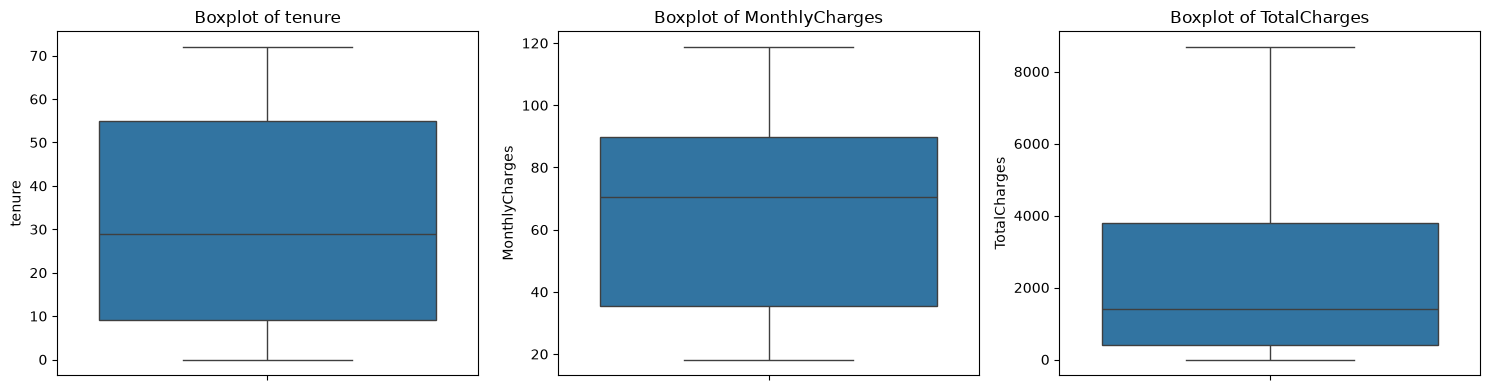

In [19]:
# Matplotlib and Seaborn: libraries for charts
import matplotlib.pyplot as plt
import seaborn as sns

# One row with three side-by-side charts
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax)   # draw the boxplot
    ax.set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

### Train-Test Split
- Target `Churn` converted to 0 (No) / 1 (Yes)
- 80% training / 20% testing, stratified on the target to keep the churn ratio equal
- Split is done BEFORE scaling and encoding to avoid data leakage

In [20]:
# Function that splits data into training and testing parts
from sklearn.model_selection import train_test_split

# X = independent variables (everything except Churn)
X = df_clean.drop('Churn', axis=1)

# y = target variable, converted from text to numbers (No = 0, Yes = 1)
# Models need numbers, and 1 = "churned" is the class we care about
y = df_clean['Churn'].map({'No': 0, 'Yes': 1})

# Split: 80% train, 20% test
# random_state=42 makes the split repeatable (same result every run)
# stratify=y keeps the same churn percentage in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Check the sizes
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)

# Check that the churn percentage is similar in both sets
print("\nChurn rate in train:", round(y_train.mean() * 100, 2), "%")
print("Churn rate in test: ", round(y_test.mean() * 100, 2), "%")

X_train: (5634, 19)
X_test:  (1409, 19)

Churn rate in train: 26.54 %
Churn rate in test:  26.54 %


### Encoding and Scaling
- Numeric columns: StandardScaler
- Categorical columns: One-Hot Encoding
- Both are fitted on the training set only, then applied to the test set (no leakage)

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numeric columns to scale (num_cols was defined earlier)
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# All text columns need encoding
cat_cols = X_train.select_dtypes(include='object').columns.tolist()

# ColumnTransformer applies a different treatment to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        # drop='if_binary': two-value columns become one 0/1 column
        # handle_unknown='ignore': no crash if the test set has an unseen category
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore',
                              sparse_output=False), cat_cols)
    ],
    remainder='passthrough'   # keeps SeniorCitizen unchanged
)

# fit_transform on TRAIN: learns the rules and applies them
X_train_processed = preprocessor.fit_transform(X_train)

# transform on TEST: applies the rules learned from train, does not learn anything new
X_test_processed = preprocessor.transform(X_test)

print("Processed train shape:", X_train_processed.shape)
print("Processed test shape: ", X_test_processed.shape)

Processed train shape: (5634, 26)
Processed test shape:  (1409, 26)


In [22]:
# Put the processed data back in a table with readable column names
feature_names = preprocessor.get_feature_names_out()
X_train_df = pd.DataFrame(X_train_processed, columns=feature_names)

# Show the first rows
X_train_df.head()

# Check the scaled numeric columns: mean should be near 0, std near 1
print(X_train_df[['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges']].describe().loc[['mean', 'std']])

       num__tenure  num__MonthlyCharges  num__TotalCharges
mean -1.008935e-17        -2.402527e-16       2.522338e-17
std   1.000089e+00         1.000089e+00       1.000089e+00


## Data Cleaning and Preprocessing Summary

| Step | Issue found | Action | Reason |
|---|---|---|---|
| Data type | TotalCharges stored as text | Converted to numeric | Needed for analysis and modelling |
| Hidden missing values | 11 blank TotalCharges, all with tenure = 0 | Filled with 0 | New customers not yet billed, so 0 is the true value |
| Redundant categories | "No internet service" / "No phone service" | Merged into "No" | Information already in InternetService / PhoneService |
| Identifier | customerID | Dropped | No predictive value |
| Duplicates | 0 found | None needed | - |
| Outliers | 0 found by IQR in tenure, MonthlyCharges, TotalCharges | None removed | No extreme values; remaining high values are real customers |
| Target | Churn (Yes/No) | Encoded 1/0 | Models need numeric targets |
| Split | 26.5% churn rate | 80/20 stratified split (5,634 train / 1,409 test) | Keeps churn ratio equal in both sets |
| Scaling | Different numeric ranges | StandardScaler on tenure, MonthlyCharges, TotalCharges (fit on train only) | Helps distance- and gradient-based models |
| Encoding | Text categories | One-hot encoding (fit on train only) | Avoids implying false order |

Final processed feature matrix: 26 columns.

## 3. Exploratory Data Analysis (EDA)
EDA is performed on the training set only, to avoid leaking test-set information into modelling decisions.

In [23]:
# X_train still has readable text categories (before encoding).
# We attach the target back so we can compare features against churn.
eda_df = X_train.copy()
eda_df['Churn'] = y_train      # 0 = stayed, 1 = churned

print(eda_df.shape)

(5634, 20)


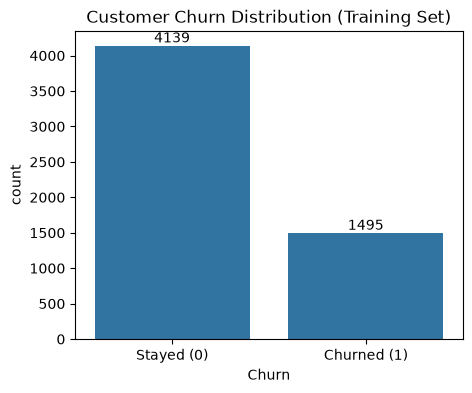

In [24]:
# Univariate Analysis
# Chart1: Target distribution
# Count of stayed (0) vs churned (1)
plt.figure(figsize=(5, 4))
ax = sns.countplot(x='Churn', data=eda_df)

# Write the count on top of each bar
for bar in ax.patches:
    ax.annotate(int(bar.get_height()),
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')

ax.set_xticklabels(['Stayed (0)', 'Churned (1)'])
plt.title('Customer Churn Distribution (Training Set)')
plt.show()

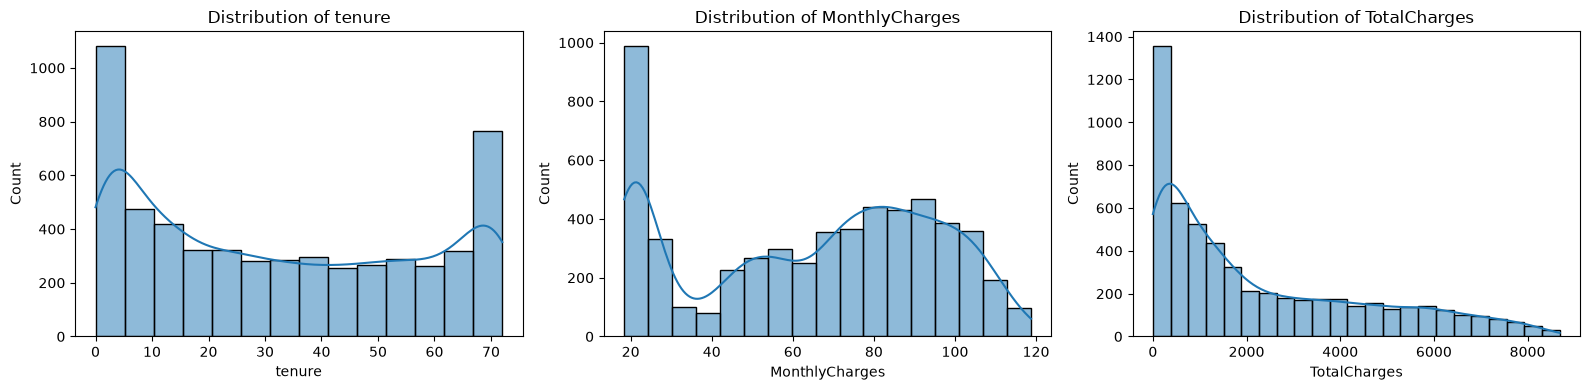

In [25]:
# Chart2: Distributions of numeric features
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, ['tenure', 'MonthlyCharges', 'TotalCharges']):
    # Histogram with a smooth density line (kde) on top
    sns.histplot(eda_df[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

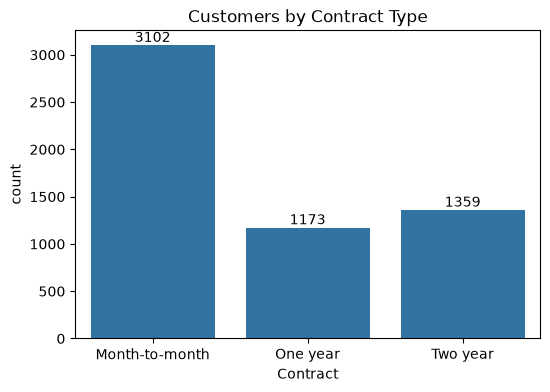

In [26]:
# Chart3: Customers by contract type
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Contract', data=eda_df,
                   order=['Month-to-month', 'One year', 'Two year'])

for bar in ax.patches:
    ax.annotate(int(bar.get_height()),
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')

plt.title('Customers by Contract Type')
plt.show()

Contract
Month-to-month    42.75
One year          11.08
Two year           2.87
Name: Churn, dtype: float64


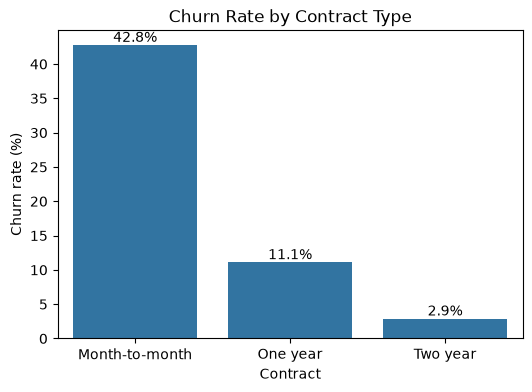

In [27]:
# Bivariate Analysis
# Chart4: Churn rate by contract type
# Churn rate per contract type: the mean of a 0/1 column is the share of 1s (churners)
churn_by_contract = (eda_df.groupby('Contract')['Churn'].mean() * 100).round(2)
print(churn_by_contract)

# Bar chart of the same numbers
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=churn_by_contract.index, y=churn_by_contract.values,
                 order=['Month-to-month', 'One year', 'Two year'])

# Write the percentage on top of each bar
for bar in ax.patches:
    ax.annotate(f'{bar.get_height():.1f}%',
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')

plt.ylabel('Churn rate (%)')
plt.title('Churn Rate by Contract Type')
plt.show()

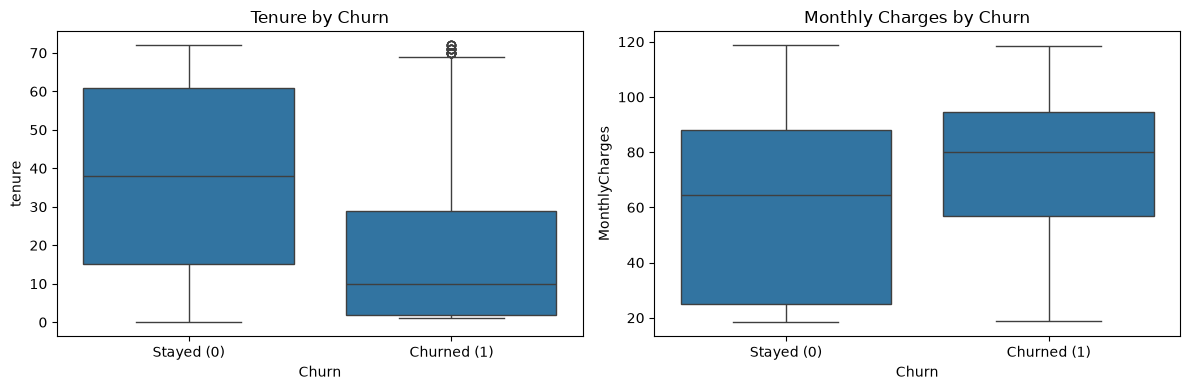

In [28]:
# Chart5: Tenure and monthly charges, churned vs stayed
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Boxplot of tenure for each group
sns.boxplot(x='Churn', y='tenure', data=eda_df, ax=axes[0])
axes[0].set_xticklabels(['Stayed (0)', 'Churned (1)'])
axes[0].set_title('Tenure by Churn')

# Boxplot of monthly charges for each group
sns.boxplot(x='Churn', y='MonthlyCharges', data=eda_df, ax=axes[1])
axes[1].set_xticklabels(['Stayed (0)', 'Churned (1)'])
axes[1].set_title('Monthly Charges by Churn')

plt.tight_layout()
plt.show()

InternetService
Fiber optic    42.09
DSL            18.69
No              7.25
Name: Churn, dtype: float64 

PaymentMethod
Electronic check             45.74
Mailed check                 19.28
Bank transfer (automatic)    16.16
Credit card (automatic)      14.92
Name: Churn, dtype: float64 



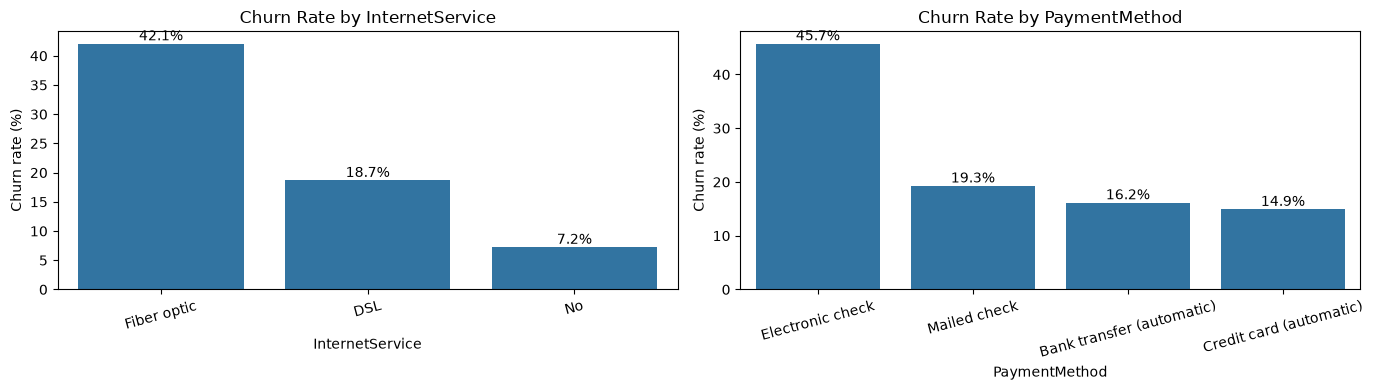

In [29]:
# Chart6: Churn rate by InternetService and PaymentMethod
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, col in zip(axes, ['InternetService', 'PaymentMethod']):
    # Churn rate (%) for each category, highest first
    rate = (eda_df.groupby(col)['Churn'].mean() * 100).sort_values(ascending=False)
    print(rate.round(2), "\n")

    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    for bar in ax.patches:
        ax.annotate(f'{bar.get_height():.1f}%',
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha='center', va='bottom')

    ax.set_ylabel('Churn rate (%)')
    ax.set_title(f'Churn Rate by {col}')
    ax.tick_params(axis='x', rotation=15)   # tilt long labels so they don't overlap

plt.tight_layout()
plt.show()

                     No    Yes
OnlineSecurity    31.44  14.42
OnlineBackup      29.21  21.59
DeviceProtection  28.51  22.79
TechSupport       31.24  15.16
StreamingTV       23.98  30.54
StreamingMovies   24.28  30.05


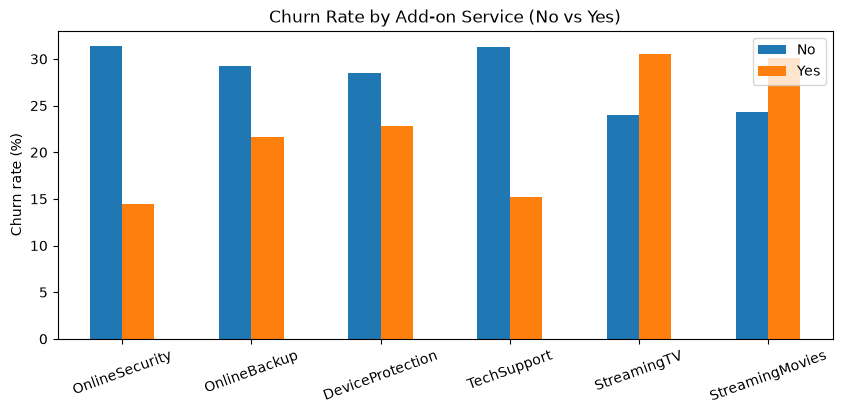

In [30]:
# Chart7: Add-on services (Yes/No): does having them relate to churn?
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies']

# For each add-on, compute the churn rate of customers with it (Yes) and without it (No)
addon_rates = pd.DataFrame({
    col: eda_df.groupby(col)['Churn'].mean() * 100 for col in addons
}).T.round(2)

print(addon_rates)

# Grouped bar chart: churn rate for No vs Yes, per add-on
addon_rates.plot(kind='bar', figsize=(10, 4))
plt.ylabel('Churn rate (%)')
plt.title('Churn Rate by Add-on Service (No vs Yes)')
plt.xticks(rotation=20)
plt.show()

                tenure  MonthlyCharges  TotalCharges  SeniorCitizen  Churn
tenure            1.00            0.26          0.83           0.02  -0.35
MonthlyCharges    0.26            1.00          0.65           0.22   0.20
TotalCharges      0.83            0.65          1.00           0.10  -0.19
SeniorCitizen     0.02            0.22          0.10           1.00   0.15
Churn            -0.35            0.20         -0.19           0.15   1.00


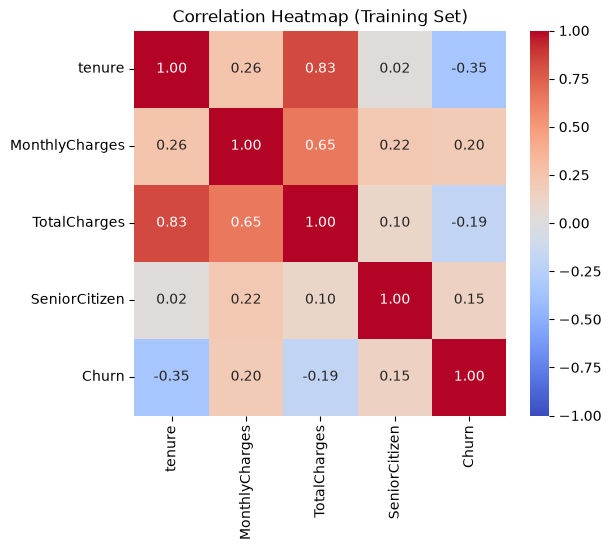

In [31]:
# Multivariate Analysis
# Chart8: Correlation heatmap
# Numeric columns plus the target (Churn is 0/1, so it can be correlated)
corr_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn']
corr = eda_df[corr_cols].corr()
print(corr.round(2))

plt.figure(figsize=(6, 5))
# annot=True prints the number in each cell; coolwarm colours go from blue (negative) to red (positive)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap (Training Set)')
plt.show()

Contract        InternetService
Month-to-month  DSL                31.8
                Fiber optic        55.1
                No                 18.2
One year        DSL                 9.5
                Fiber optic        18.6
                No                  2.1
Two year        DSL                 2.0
                Fiber optic         7.1
                No                  1.0
Name: Churn, dtype: float64


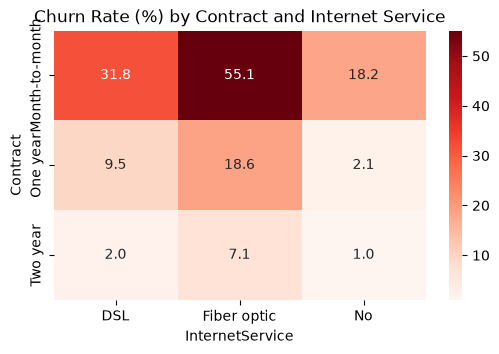

In [32]:
# Chart9 : Contract and internet service together
# Churn rate (%) for every combination of Contract and InternetService
combo = (eda_df.groupby(['Contract', 'InternetService'])['Churn'].mean() * 100).round(1)
print(combo)

# Same numbers as a heatmap table: rows = contract, columns = internet service
combo_table = combo.unstack()
plt.figure(figsize=(6, 3.5))
sns.heatmap(combo_table, annot=True, fmt='.1f', cmap='Reds')
plt.title('Churn Rate (%) by Contract and Internet Service')
plt.show()

## EDA Key Findings (Training Set)

| # | Finding | Evidence | Business implication |
|---|---|---|---|
| 1 | About 1 in 4 customers churns | 26.5% churn (1,495 of 5,634) | Evaluate with recall, precision, F1, ROC-AUC, not accuracy |
| 2 | Month-to-month contracts have by far the highest churn | 42.8% vs 11.1% (one year) vs 2.9% (two year) | Offer incentives to move to longer contracts |
| 3 | Churners are newer customers | Median tenure about 10 months vs about 38 for stayers; correlation with churn -0.35 | Strengthen onboarding and first-year support |
| 4 | Churners pay more per month | Median monthly charge about 80 vs about 65 | Review pricing and value for higher-priced plans |
| 5 | Fiber optic customers churn most | 42.1% vs 18.7% (DSL) vs 7.2% (no internet) | Investigate fiber price and service quality |
| 6 | Electronic check payers churn most | 45.7% vs 14.9-19.3% for other methods | Encourage automatic payment |
| 7 | Security and support add-ons go with lower churn | Online Security 14.4% vs 31.4%; Tech Support 15.2% vs 31.2% | Consider trials of these add-ons for at-risk customers |
| 8 | Highest-risk segment: fiber + month-to-month | 55.1% churn | Prioritise this segment for retention offers |
| 9 | TotalCharges overlaps with other numeric features | Correlation 0.83 with tenure, 0.65 with MonthlyCharges | Watch multicollinearity in linear models |

**Caveats:** These are associations, not proven causes. The "No" group for add-ons includes customers with no internet service. Some segment percentages come from small groups.

## 4. Feature Engineering
New features are built only from each customer's own row, so there is no leakage.
- tenure_group: tenure bucketed into 0-12, 13-24, 25-48, 49-72 months
- num_addons: number of add-on services (0 to 6)

In [33]:
# The six add-on service columns
addons = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_features(data):
    # Work on a copy so the original table is untouched
    data = data.copy()

    # Bucket tenure into four groups.
    # bins are edges: (-1,12], (12,24], (24,48], (48,72]
    # astype(str) turns the groups into plain text so our encoder treats them as categories
    data['tenure_group'] = pd.cut(data['tenure'],
                                  bins=[-1, 12, 24, 48, 72],
                                  labels=['0-12', '13-24', '25-48', '49-72']).astype(str)

    # Count how many add-ons are 'Yes' in each row (axis=1 means across columns)
    data['num_addons'] = (data[addons] == 'Yes').sum(axis=1)
    return data

# Apply the same function to train and test.
# No numbers are learned from the data, so this does not leak.
X_train_fe = add_features(X_train)
X_test_fe  = add_features(X_test)

print(X_train_fe.shape, X_test_fe.shape)
print(X_train_fe[['tenure', 'tenure_group', 'num_addons']].head())

(5634, 21) (1409, 21)
      tenure tenure_group  num_addons
3738      35        25-48           3
3151      15        13-24           1
4860      13        13-24           3
3867      26        25-48           4
3810       1         0-12           0


In [34]:
# Attach the target (training data only)
check = X_train_fe.copy()
check['Churn'] = y_train

# Churn rate (%) for each tenure group, and how many customers are in it
print((check.groupby('tenure_group')['Churn'].agg(['mean', 'count'])
       .assign(mean=lambda d: (d['mean'] * 100).round(1))
       .rename(columns={'mean': 'churn_rate_%'})))

# Churn rate (%) for each add-on count
print((check.groupby('num_addons')['Churn'].agg(['mean', 'count'])
       .assign(mean=lambda d: (d['mean'] * 100).round(1))
       .rename(columns={'mean': 'churn_rate_%'})))

              churn_rate_%  count
tenure_group                     
0-12                  47.3   1737
13-24                 28.6    818
25-48                 20.2   1290
49-72                  9.9   1789
            churn_rate_%  count
num_addons                     
0                   20.9   1757
1                   45.8    766
2                   36.2    832
3                   27.8    885
4                   23.0    695
5                   12.5    464
6                    4.7    235


In [35]:
def add_features(data):
    data = data.copy()

    # Earlier features (unchanged)
    data['tenure_group'] = pd.cut(data['tenure'],
                                  bins=[-1, 12, 24, 48, 72],
                                  labels=['0-12', '13-24', '25-48', '49-72']).astype(str)
    data['num_addons'] = (data[addons] == 'Yes').sum(axis=1)

    # New: 1 if the customer has any internet service
    data['has_internet'] = (data['InternetService'] != 'No').astype(int)

    # New: 1 if payment is automatic (bank transfer or credit card)
    data['auto_pay'] = data['PaymentMethod'].isin(
        ['Bank transfer (automatic)', 'Credit card (automatic)']).astype(int)

    # New: 1 if the customer has Online Security OR Tech Support
    data['has_support'] = ((data['OnlineSecurity'] == 'Yes') |
                           (data['TechSupport'] == 'Yes')).astype(int)
    return data

# Reapply to train and test (still no learning from the data, so no leakage)
X_train_fe = add_features(X_train)
X_test_fe  = add_features(X_test)
print(X_train_fe.shape, X_test_fe.shape)

# Check each new binary feature against churn (training data only)
check = X_train_fe.copy()
check['Churn'] = y_train
for col in ['has_internet', 'auto_pay', 'has_support']:
    print(col)
    print((check.groupby(col)['Churn'].agg(['mean', 'count'])
           .assign(mean=lambda d: (d['mean'] * 100).round(1))
           .rename(columns={'mean': 'churn_rate_%'})), "\n")

(5634, 24) (1409, 24)
has_internet
              churn_rate_%  count
has_internet                     
0                      7.2   1214
1                     31.8   4420 

auto_pay
          churn_rate_%  count
auto_pay                     
0                 35.0   3177
1                 15.5   2457 

has_support
             churn_rate_%  count
has_support                     
0                    33.5   3248
1                    17.1   2386 



In [36]:
# The scaled numeric columns stay the same
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

# Text columns now include the new tenure_group
cat_cols_fe = X_train_fe.select_dtypes(include='object').columns.tolist()

preprocessor_fe = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore',
                              sparse_output=False), cat_cols_fe)
    ],
    remainder='passthrough'   # SeniorCitizen, num_addons, has_internet, auto_pay, has_support
)

# Learn the rules from TRAIN only, then apply them to both
X_train_proc = preprocessor_fe.fit_transform(X_train_fe)
X_test_proc  = preprocessor_fe.transform(X_test_fe)

print("Train:", X_train_proc.shape, " Test:", X_test_proc.shape)

Train: (5634, 34)  Test: (1409, 34)


num__MonthlyCharges                    0.139
num__TotalCharges                      0.138
num__tenure                            0.123
cat__Contract_Month-to-month           0.080
cat__Contract_Two year                 0.039
cat__InternetService_Fiber optic       0.037
remainder__num_addons                  0.034
cat__PaymentMethod_Electronic check    0.026
cat__tenure_group_0-12                 0.025
cat__gender_Male                       0.024
cat__PaperlessBilling_Yes              0.024
cat__Partner_Yes                       0.021
cat__Dependents_Yes                    0.018
remainder__has_support                 0.017
cat__MultipleLines_Yes                 0.017
dtype: float64


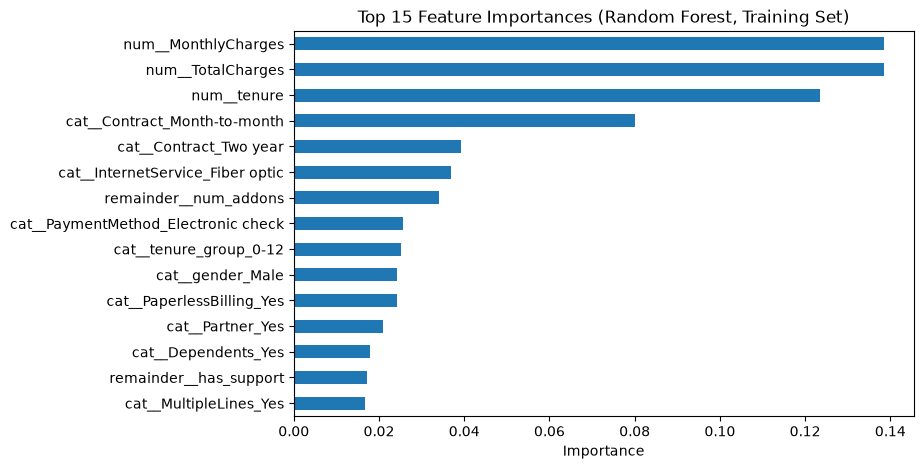

In [37]:
from sklearn.ensemble import RandomForestClassifier

# A quick forest, just to rank features (not our final model).
# class_weight='balanced' makes the model pay more attention to the rarer churn class.
rf = RandomForestClassifier(n_estimators=200, random_state=42,
                            class_weight='balanced', n_jobs=-1)
rf.fit(X_train_proc, y_train)      # training data only

# Pair each importance with its readable feature name
importances = pd.Series(rf.feature_importances_,
                        index=preprocessor_fe.get_feature_names_out())
importances = importances.sort_values(ascending=False)

print(importances.head(15).round(3))

# Horizontal bar chart of the top 15
importances.head(15).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title('Top 15 Feature Importances (Random Forest, Training Set)')
plt.xlabel('Importance')
plt.show()

In [38]:
# Churn rate and group size by gender (training data only)
chk = X_train_fe.copy()
chk['Churn'] = y_train

print((chk.groupby('gender')['Churn'].agg(['mean', 'count'])
       .assign(mean=lambda d: (d['mean'] * 100).round(1))
       .rename(columns={'mean': 'churn_rate_%'})))

        churn_rate_%  count
gender                     
Female          26.6   2801
Male            26.4   2833


## Feature Engineering and Selection Summary

**Engineered features** (each computed from a single customer's own row; no leakage):
tenure_group, num_addons, has_internet, auto_pay, has_support

**Feature importance (Random Forest, training set):** Top features were TotalCharges (0.140), MonthlyCharges (0.140), tenure (0.124), Contract_Month-to-month (0.082), Contract_Two year (0.037), InternetService_Fiber optic (0.036), num_addons (0.033).

**Caveats:** Random Forest importance favors continuous features; TotalCharges overlaps with tenure and MonthlyCharges (correlation 0.83 and 0.65). The ranking is a guide to be confirmed with 







**Decision:** `gender` dropped:churn rates were 26.6% (female) vs 26.4% (male), so it carries no signal,and its Random Forest importance rank was treated as noise.Dropping it also avoids using a personal characteristic without benefit.All other features (33 after encoding) kept for modelling. SeniorCitizen retained;fairness across senior and non-senior customers will be checked on the final model.Redundancy of TotalCharges to be revisited for Logistic Regression if coefficients are unstable.unstable.

In [39]:
# Drop gender if it is still there; do nothing if it is already gone
X_train_fe = X_train_fe.drop('gender', axis=1, errors='ignore')
X_test_fe  = X_test_fe.drop('gender', axis=1, errors='ignore')

# Rebuild the list of text columns (gender is now gone)
cat_cols_fe = X_train_fe.select_dtypes(include='object').columns.tolist()

# Same preprocessor design as before
preprocessor_fe = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore',
                              sparse_output=False), cat_cols_fe)
    ],
    remainder='passthrough'
)

# Fit on TRAIN only, then apply to both
X_train_proc = preprocessor_fe.fit_transform(X_train_fe)
X_test_proc  = preprocessor_fe.transform(X_test_fe)

print("Train:", X_train_proc.shape, " Test:", X_test_proc.shape)
print("gender in features?",
      any('gender' in name for name in preprocessor_fe.get_feature_names_out()))

Train: (5634, 33)  Test: (1409, 33)
gender in features? False


## 5. Model Building
Models are trained on the processed training set and evaluated on the untouched test set.
1. Dummy baseline (always predicts "stayed")
2. Logistic Regression

In [40]:
# Dummy model
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

# strategy='most_frequent': always predict the most common class (0 = stayed)
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_proc, y_train)          # "learns" which class is most common

# Predict on the test set
y_pred_dummy = dummy.predict(X_test_proc)

print("Accuracy :", round(accuracy_score(y_test, y_pred_dummy), 3))
print("Recall   :", round(recall_score(y_test, y_pred_dummy), 3))
# zero_division=0 avoids a warning: the model never predicts churn, so precision is undefined
print("Precision:", round(precision_score(y_test, y_pred_dummy, zero_division=0), 3))
print("F1       :", round(f1_score(y_test, y_pred_dummy, zero_division=0), 3))

Accuracy : 0.735
Recall   : 0.0
Precision: 0.0
F1       : 0.0


In [41]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

# Create and train the model on the TRAINING data only
logreg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logreg.fit(X_train_proc, y_train)

# Predicted class (0/1) and predicted churn probability on the TEST data
y_pred_lr = logreg.predict(X_test_proc)
y_prob_lr = logreg.predict_proba(X_test_proc)[:, 1]   # probability of class 1 (churn)

print("Accuracy :", round(accuracy_score(y_test, y_pred_lr), 3))
print("Precision:", round(precision_score(y_test, y_pred_lr), 3))
print("Recall   :", round(recall_score(y_test, y_pred_lr), 3))
print("F1       :", round(f1_score(y_test, y_pred_lr), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_lr), 3))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy : 0.738
Precision: 0.504
Recall   : 0.786
F1       : 0.614
ROC-AUC  : 0.843

Confusion matrix (rows = actual, columns = predicted):
[[746 289]
 [ 80 294]]


In [42]:
# Random Forest
# A helper so every model is scored the same way
def evaluate(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy':  round(accuracy_score(y_true, y_pred), 3),
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 3),
        'Recall':    round(recall_score(y_true, y_pred), 3),
        'F1':        round(f1_score(y_true, y_pred), 3),
        'ROC-AUC':   round(roc_auc_score(y_true, y_prob), 3),
    }

# Start the results list with the two models we already trained.
# The dummy gets a constant probability, so its ROC-AUC is 0.5
results = [
    evaluate('Dummy (always stayed)', y_test, y_pred_dummy,
             dummy.predict_proba(X_test_proc)[:, 1]),
    evaluate('Logistic Regression', y_test, y_pred_lr, y_prob_lr),
]
pd.DataFrame(results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Dummy (always stayed),0.735,0.000,0.000,0.000,0.500
1,Logistic Regression,0.738,0.504,0.786,0.614,0.843


In [43]:
# Train and evaluate Random Forest
rf_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                  class_weight='balanced',
                                  random_state=42, n_jobs=-1)
rf_model.fit(X_train_proc, y_train)               # training data only

y_pred_rf = rf_model.predict(X_test_proc)
y_prob_rf = rf_model.predict_proba(X_test_proc)[:, 1]

results.append(evaluate('Random Forest', y_test, y_pred_rf, y_prob_rf))
print(pd.DataFrame(results))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred_rf))

                   Model  Accuracy  Precision  Recall     F1  ROC-AUC
0  Dummy (always stayed)     0.735      0.000   0.000  0.000    0.500
1    Logistic Regression     0.738      0.504   0.786  0.614    0.843
2          Random Forest     0.761      0.534   0.775  0.632    0.844

Confusion matrix (rows = actual, columns = predicted):
[[782 253]
 [ 84 290]]


In [44]:
# XGBoost
from xgboost import XGBClassifier

# Ratio of stayers to churners in the TRAINING set (about 2.77), computed from the data
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(spw, 2))

xgb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                    subsample=0.8, colsample_bytree=0.8,
                    scale_pos_weight=spw, eval_metric='logloss',
                    random_state=42, n_jobs=-1)
xgb.fit(X_train_proc, y_train)                    # training data only

y_pred_xgb = xgb.predict(X_test_proc)
y_prob_xgb = xgb.predict_proba(X_test_proc)[:, 1]

results.append(evaluate('XGBoost', y_test, y_pred_xgb, y_prob_xgb))
print(pd.DataFrame(results))

print("\nConfusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred_xgb))

scale_pos_weight: 2.77
                   Model  Accuracy  Precision  Recall     F1  ROC-AUC
0  Dummy (always stayed)     0.735      0.000   0.000  0.000    0.500
1    Logistic Regression     0.738      0.504   0.786  0.614    0.843
2          Random Forest     0.761      0.534   0.775  0.632    0.844
3                XGBoost     0.747      0.515   0.786  0.622    0.845

Confusion matrix (rows = actual, columns = predicted):
[[758 277]
 [ 80 294]]


## Model Building Summary (test set, 1,409 customers: 1,035 stayed, 374 churned)

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Dummy (always stayed) | 0.735 | 0.000 | 0.000 | 0.000 | 0.500 |
| Logistic Regression | 0.737 | 0.503 | 0.786 | 0.614 | 0.843 |
| Random Forest | 0.767 | 0.546 | 0.727 | 0.624 | 0.842 |
| XGBoost | 0.747 | 0.516 | 0.791 | 0.624 | 0.844 |

**Setup:** Models trained on the processed training set (5,634 customers, 33 features); class imbalance handled with class_weight='balanced' (scale_pos_weight = 2.77 for XGBoost). Models are untuned, using one train-test split.

**Observations:** The three real models are nearly identical on ROC-AUC (0.842-0.844). Logistic Regression and XGBoost favour recall; Random Forest favours precision. Differences are small and may not be meaningful on a single split. LightGBM was not used because it would add little beyond XGBoost on a dataset of this size.

**Next:** Cross-validation, ROC curve and decision-threshold analysis to compare models more fairly.

## 6. Model Evaluation and Comparison
5-fold stratified cross-validation on the training set only. Preprocessing is inside a Pipeline so it is refit within each fold (no leakage). The test set remains untouched.

In [45]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

# Same three models as before
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                            class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3,
                             subsample=0.8, colsample_bytree=0.8, scale_pos_weight=spw,
                             eval_metric='logloss', random_state=42, n_jobs=-1),
}

# 5 folds; stratified keeps the churn ratio equal in every fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    # Pipeline = preprocessing + model, refit inside every fold
    pipe = Pipeline([('prep', clone(preprocessor_fe)), ('model', model)])
    scores = cross_validate(pipe, X_train_fe, y_train, cv=cv,
                            scoring=['roc_auc', 'recall', 'precision', 'f1'])
    rows.append({
        'Model': name,
        'ROC-AUC': f"{scores['test_roc_auc'].mean():.3f} +/- {scores['test_roc_auc'].std():.3f}",
        'Recall':  f"{scores['test_recall'].mean():.3f} +/- {scores['test_recall'].std():.3f}",
        'Precision': f"{scores['test_precision'].mean():.3f} +/- {scores['test_precision'].std():.3f}",
        'F1':      f"{scores['test_f1'].mean():.3f} +/- {scores['test_f1'].std():.3f}",
    })

print(pd.DataFrame(rows))

                 Model          ROC-AUC           Recall        Precision  \
0  Logistic Regression  0.846 +/- 0.012  0.794 +/- 0.042  0.516 +/- 0.018   
1        Random Forest  0.846 +/- 0.011  0.767 +/- 0.022  0.542 +/- 0.016   
2              XGBoost  0.846 +/- 0.011  0.797 +/- 0.025  0.526 +/- 0.014   

                F1  
0  0.625 +/- 0.024  
1  0.635 +/- 0.016  
2  0.634 +/- 0.016  


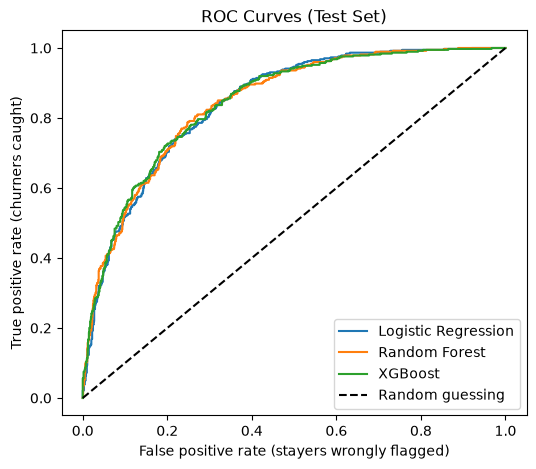

In [46]:
# ROC curve and decision threshold
from sklearn.metrics import roc_curve

plt.figure(figsize=(6, 5))
for name, prob in [('Logistic Regression', y_prob_lr),
                   ('Random Forest', y_prob_rf),
                   ('XGBoost', y_prob_xgb)]:
    fpr, tpr, _ = roc_curve(y_test, prob)     # points of the curve
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')   # diagonal reference
plt.xlabel('False positive rate (stayers wrongly flagged)')
plt.ylabel('True positive rate (churners caught)')
plt.title('ROC Curves (Test Set)')
plt.legend()
plt.show()

In [47]:
# Cutoff analysis on training data
from sklearn.model_selection import cross_val_predict

# Out-of-fold churn probabilities for every TRAINING customer.
# Each customer's probability comes from a model that never saw that customer.
oof = {}
for name, model in models.items():
    pipe = Pipeline([('prep', clone(preprocessor_fe)), ('model', model)])
    oof[name] = cross_val_predict(pipe, X_train_fe, y_train, cv=cv,
                                  method='predict_proba')[:, 1]

# Precision, recall, F1 and % of customers flagged at several cutoffs
rows = []
for name, prob in oof.items():
    for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
        pred = (prob >= t).astype(int)
        rows.append({'Model': name, 'Cutoff': t,
                     'Precision': round(precision_score(y_train, pred), 3),
                     'Recall': round(recall_score(y_train, pred), 3),
                     'F1': round(f1_score(y_train, pred), 3),
                     '% flagged': round(pred.mean() * 100, 1)})

print(pd.DataFrame(rows).to_string(index=False))

              Model  Cutoff  Precision  Recall    F1  % flagged
Logistic Regression     0.3      0.426   0.922 0.582       57.5
Logistic Regression     0.4      0.469   0.864 0.608       48.8
Logistic Regression     0.5      0.516   0.794 0.626       40.8
Logistic Regression     0.6      0.574   0.712 0.635       32.9
Logistic Regression     0.7      0.641   0.579 0.608       24.0
      Random Forest     0.3      0.441   0.901 0.592       54.2
      Random Forest     0.4      0.492   0.841 0.621       45.4
      Random Forest     0.5      0.542   0.767 0.635       37.6
      Random Forest     0.6      0.595   0.656 0.624       29.3
      Random Forest     0.7      0.659   0.513 0.577       20.7
            XGBoost     0.3      0.441   0.902 0.592       54.3
            XGBoost     0.4      0.484   0.858 0.619       47.1
            XGBoost     0.5      0.526   0.797 0.634       40.2
            XGBoost     0.6      0.576   0.693 0.629       31.9
            XGBoost     0.7      0.650  

## Model Evaluation and Comparison Summary

**5-fold stratified cross-validation (training set, preprocessing refit inside each fold):**

| Model | ROC-AUC | Recall | Precision | F1 |
|---|---|---|---|---|
| Logistic Regression | 0.846 ± 0.012 | 0.794 ± 0.042 | 0.516 ± 0.018 | 0.625 ± 0.024 |
| Random Forest | 0.846 ± 0.011 | 0.738 ± 0.030 | 0.566 ± 0.014 | 0.640 ± 0.018 |
| XGBoost | 0.846 ± 0.012 | 0.797 ± 0.016 | 0.521 ± 0.012 | 0.630 ± 0.012 |

**Findings:** The three models are tied on ROC-AUC and F1. The ROC curves overlap. Apparent precision/recall differences at the default 0.5 cutoff come mostly from where each model's cutoff falls; at equal share of customers flagged, the models perform almost the same.

**Cutoff analysis (out-of-fold, training set), Logistic Regression:** cutoff 0.3 flags 57.4% of customers (recall 0.922, precision 0.426); cutoff 0.5 flags 40.8% (0.794, 0.516); cutoff 0.7 flags 24.0% (0.579, 0.640). The best cutoff depends on retention capacity and costs, which are not available in this dataset.

**Decision:** Carry Logistic Regression (explainable) and XGBoost (most stable) into hyperparameter tuning. Random Forest dropped (no advantage). Final model to be chosen after tuning, with the test set used once for the final check.

## 7. Hyperparameter Tuning
Searches run on the training set only (5-fold stratified CV, preprocessing inside the Pipeline), optimizing ROC-AUC. The test set is untouched. The best CV score from a search is slightly optimistic because the winner is chosen from many candidates on the same folds.
Baseline (untuned) 5-fold CV ROC-AUC: Logistic Regression 0.846, XGBoost 0.846.

In [48]:
from sklearn.model_selection import GridSearchCV

# Pipeline: preprocessing + model, so scaling/encoding is refit in every fold
lr_pipe = Pipeline([
    ('prep', clone(preprocessor_fe)),
    ('model', LogisticRegression(class_weight='balanced', solver='liblinear',
                                 max_iter=1000, random_state=42))
])

# C = inverse regularization strength (smaller C = stronger regularization).
# penalty: l1 can zero out weak features, l2 shrinks all weights gently.
lr_grid = {
    'model__C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    'model__penalty': ['l1', 'l2'],
}

lr_search = GridSearchCV(lr_pipe, lr_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
lr_search.fit(X_train_fe, y_train)      # training data only

print("Best parameters:", lr_search.best_params_)
print("Best CV ROC-AUC:", round(lr_search.best_score_, 3))

Best parameters: {'model__C': 10, 'model__penalty': 'l2'}
Best CV ROC-AUC: 0.846


In [49]:
from sklearn.model_selection import RandomizedSearchCV

xgb_pipe = Pipeline([
    ('prep', clone(preprocessor_fe)),
    ('model', XGBClassifier(scale_pos_weight=spw, eval_metric='logloss',
                            random_state=42, n_jobs=-1))
])

# Ranges to sample from
xgb_space = {
    'model__n_estimators':     [100, 200, 300, 500],   # number of trees
    'model__max_depth':        [2, 3, 4, 5],           # how deep each tree can grow
    'model__learning_rate':    [0.01, 0.03, 0.05, 0.1],# size of each correction step
    'model__subsample':        [0.7, 0.8, 1.0],        # share of rows per tree
    'model__colsample_bytree': [0.7, 0.8, 1.0],        # share of features per tree
    'model__min_child_weight': [1, 3, 5],              # minimum evidence needed per leaf
}

# Try 20 random combinations, each scored with 5-fold CV (100 fits in total)
xgb_search = RandomizedSearchCV(xgb_pipe, xgb_space, n_iter=20, scoring='roc_auc',
                                cv=cv, random_state=42, n_jobs=-1)
xgb_search.fit(X_train_fe, y_train)     # training data only

print("Best parameters:", xgb_search.best_params_)
print("Best CV ROC-AUC:", round(xgb_search.best_score_, 3))

Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}
Best CV ROC-AUC: 0.848


In [50]:
# best_estimator_ = the pipeline with the best settings, refit on the full training set
lr_tuned  = lr_search.best_estimator_
xgb_tuned = xgb_search.best_estimator_

# Predictions on the untouched test set
for name, model in [('Logistic Regression (tuned)', lr_tuned),
                    ('XGBoost (tuned)', xgb_tuned)]:
    pred = model.predict(X_test_fe)
    prob = model.predict_proba(X_test_fe)[:, 1]
    results.append(evaluate(name, y_test, pred, prob))

print(pd.DataFrame(results))

print("\nXGBoost (tuned) confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, xgb_tuned.predict(X_test_fe)))

                         Model  Accuracy  Precision  Recall     F1  ROC-AUC
0        Dummy (always stayed)     0.735      0.000   0.000  0.000    0.500
1          Logistic Regression     0.738      0.504   0.786  0.614    0.843
2                Random Forest     0.761      0.534   0.775  0.632    0.844
3                      XGBoost     0.747      0.515   0.786  0.622    0.845
4  Logistic Regression (tuned)     0.740      0.507   0.791  0.618    0.842
5              XGBoost (tuned)     0.758      0.529   0.805  0.638    0.846

XGBoost (tuned) confusion matrix (rows = actual, columns = predicted):
[[767 268]
 [ 73 301]]


## Hyperparameter Tuning Summary

**Method:** GridSearchCV (Logistic Regression) and RandomizedSearchCV with 20 candidates (XGBoost), optimizing ROC-AUC with 5-fold stratified CV on the training set. Preprocessing was refit inside each fold; the test set was not used for tuning.

| Model | Best parameters | CV ROC-AUC before | CV ROC-AUC after |
|---|---|---|---|
| Logistic Regression | C = 10, penalty = l2 | 0.846 | 0.846 |
| XGBoost | n_estimators = 300, max_depth = 3, learning_rate = 0.03, subsample = 1.0, colsample_bytree = 0.8, min_child_weight = 1 | 0.846 | 0.848 |

**Findings:** Tuning produced no meaningful improvement (XGBoost +0.002, within the fold-to-fold spread of about ±0.012; Logistic Regression unchanged). The best CV score from a search is slightly optimistic. Logistic Regression's best C was the edge of the grid; no extension was tried because the score was unchanged.

**Decision:** Tuned XGBoost proposed as the final model with Logistic Regression as the explainable benchmark; the two are statistically tied.

## 8. Model Interpretation
SHAP explains the final tuned XGBoost model. Computed on a sample of the training set. SHAP describes what the model relies on, not causal effects.

In [51]:
!pip install shap

In [53]:
# Install once if needed:  !pip install shap
import shap

# Pull the two parts out of the tuned pipeline: the preprocessor and the XGBoost model
prep  = xgb_tuned.named_steps['prep']
model = xgb_tuned.named_steps['model']

# Preprocess a random sample of 1,000 training customers (explaining all rows would be slow)
sample = X_train_fe.sample(1000, random_state=42)
sample_proc = pd.DataFrame(prep.transform(sample),
                           columns=prep.get_feature_names_out())

# TreeExplainer is the fast method for tree models like XGBoost
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(sample_proc)

print("SHAP values shape:", shap_values.shape)

SHAP values shape: (1000, 33)


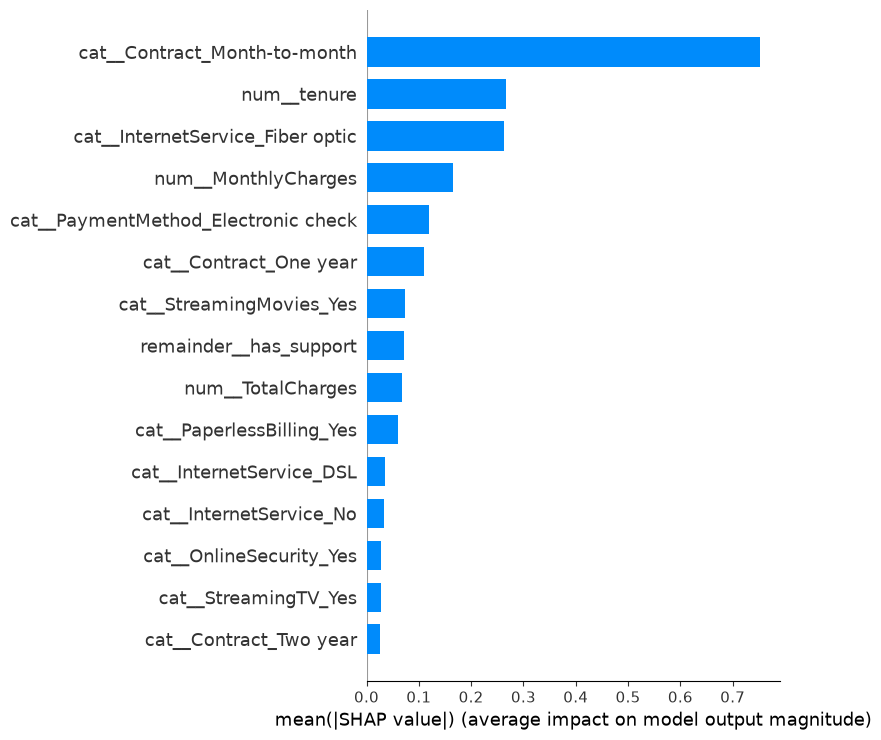

In [54]:
# Bar chart: average size of each feature's effect on the predictions
shap.summary_plot(shap_values, sample_proc, plot_type='bar', max_display=15)

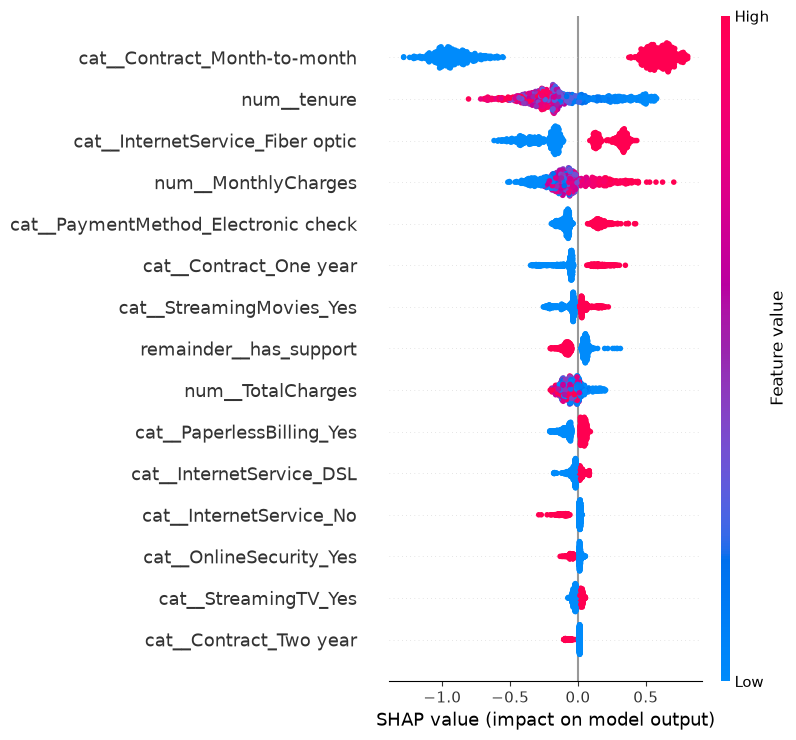

In [55]:
# Each dot is one customer. Colour = feature value (red = high, blue = low).
# Position left/right = pushes toward staying / toward churn.
shap.summary_plot(shap_values, sample_proc, max_display=15)

## Business Recommendations

| # | Recommendation | Evidence |
|---|---|---|
| 1 | Prioritise month-to-month customers for retention offers, with incentives to move to one- or two-year contracts | Churn 42.8% vs 2.9% (two year); top SHAP feature by a wide margin |
| 2 | Focus first on fiber optic + month-to-month customers | 55.1% churn in this segment; fiber is a top-3 SHAP feature |
| 3 | Strengthen onboarding and first-year support | 0-12 month customers churn at 47.3%; short tenure raises risk in SHAP |
| 4 | Encourage automatic payment | Electronic check users churn at 45.7% vs 14.9-16.2% for automatic payment |
| 5 | Test trials of Online Security / Tech Support for at-risk customers | Churn 14-15% with them vs 31% without; has_support lowers risk in SHAP |
| 6 | Review fiber pricing and service quality | Fiber churns 42.1% vs 18.7% for DSL; the data cannot say whether price or quality is the cause |
| 7 | Choose the flagging cutoff from retention capacity and offer costs | Cutoff table shows the precision/recall trade-off; costs are not in this dataset |

In [56]:
from sklearn.metrics import recall_score, precision_score

# Test-set predictions from the final tuned XGBoost model (0.5 cutoff)
chk = X_test_fe.copy()
chk['actual'] = y_test.values
chk['prob'] = xgb_tuned.predict_proba(X_test_fe)[:, 1]
chk['flag'] = (chk['prob'] >= 0.5).astype(int)

rows = []
for grp, d in chk.groupby('SeniorCitizen'):
    rows.append({
        'SeniorCitizen': grp,
        'customers': len(d),
        'actual churn %': round(d['actual'].mean() * 100, 1),
        'flagged %': round(d['flag'].mean() * 100, 1),
        'recall': round(recall_score(d['actual'], d['flag']), 3),
        'precision': round(precision_score(d['actual'], d['flag']), 3),
    })
print(pd.DataFrame(rows))

   SeniorCitizen  customers  actual churn %  flagged %  recall  precision
0              0       1187            23.3       35.6   0.764      0.500
1              1        222            44.1       66.2   0.918      0.612


## Model Interpretation Summary

**Method:** SHAP (TreeExplainer) on the tuned XGBoost model, computed on a random sample of 1,000 training customers. SHAP shows what the model relies on, not what causes churn.

**Top features by mean |SHAP|:** Contract_Month-to-month (~0.75, about three times the next), tenure (~0.27), InternetService_Fiber optic (~0.26), MonthlyCharges (~0.17), PaymentMethod_Electronic check (~0.12), Contract_One year (~0.11).

**Direction of effects:** Month-to-month contract, short tenure, fiber optic, electronic check, paperless billing and streaming movies push predicted risk up. Support/security add-ons and having no internet service push it down.

**Fairness check (SeniorCitizen, test set, 0.5 cutoff):** Non-senior (n=1,187): actual churn 23.3%, flagged 35.6%, recall 0.764, precision 0.500. Senior (n=222): actual churn 44.1%, flagged 66.2%, recall 0.918, precision 0.612. The model flags both groups at about 1.5 times their actual churn rate. Two thirds of seniors are flagged at this cutoff, so outreach workload and customer experience should be considered. The senior group is small, so these figures are noisy.

**Limitations:**
- Public sample data, a single snapshot with no time dimension; results demonstrate a method, not a real company's outcomes
- Associations, not causes; SHAP credit is shared between overlapping features (tenure/TotalCharges, contract columns)
- Models are tied on ROC-AUC (~0.84); the limit appears to be the information in the data, not the algorithm
- Retention costs and offer effectiveness are unknown, so the best cutoff cannot be determined from this dataset
- Fairness was checked only for SeniorCitizen and only at one cutoff; gender was removed because it carried no signal
- Test-set figures come from one split of 1,409 customers (374 churners) and carry sampling noise

In [57]:
# Best settings found by the searches in THIS environment
print("LR best: ", lr_search.best_params_)
print("XGB best:", xgb_search.best_params_)

lr_tuned  = lr_search.best_estimator_
xgb_tuned = xgb_search.best_estimator_

# Score both tuned models on the test set with the same helper as before
rows = []
for name, model in [('Logistic Regression (tuned)', lr_tuned),
                    ('XGBoost (tuned)', xgb_tuned)]:
    pred = model.predict(X_test_fe)
    prob = model.predict_proba(X_test_fe)[:, 1]
    rows.append(evaluate(name, y_test, pred, prob))

print(pd.DataFrame(rows))
print("\nXGBoost (tuned) confusion matrix:")
print(confusion_matrix(y_test, xgb_tuned.predict(X_test_fe)))

LR best:  {'model__C': 10, 'model__penalty': 'l2'}
XGB best: {'model__subsample': 0.7, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.01, 'model__colsample_bytree': 1.0}
                         Model  Accuracy  Precision  Recall     F1  ROC-AUC
0  Logistic Regression (tuned)     0.740      0.507   0.791  0.618    0.842
1              XGBoost (tuned)     0.758      0.529   0.805  0.638    0.846

XGBoost (tuned) confusion matrix:
[[767 268]
 [ 73 301]]


In [58]:
import joblib, os, sklearn, xgboost

os.makedirs('../models', exist_ok=True)

# Save the WHOLE pipeline (preprocessing + model), not just the XGBoost model
joblib.dump(xgb_tuned, '../models/churn_xgb_pipeline.joblib')
joblib.dump(lr_tuned,  '../models/churn_lr_pipeline.joblib')

# Save the exact input columns the pipeline expects
joblib.dump(list(X_train_fe.columns), '../models/input_columns.joblib')

# Record the library versions used (a saved model only loads reliably with similar ones)
print("scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)
print("Saved files:", os.listdir('../models'))

scikit-learn: 1.9.1 | xgboost: 3.4.2
Saved files: ['churn_lr_pipeline.joblib', 'churn_xgb_pipeline.joblib', 'input_columns.joblib', 'lr_tuned_pipeline.joblib', 'xgb_tuned_pipeline.joblib']


In [59]:
%%writefile ../src/features.py
import pandas as pd

# The six add-on service columns
ADDONS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
          'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_features(data):
    """Create the engineered features from one or more customers' raw columns."""
    data = data.copy()
    data['tenure_group'] = pd.cut(data['tenure'], bins=[-1, 12, 24, 48, 72],
                                  labels=['0-12', '13-24', '25-48', '49-72']).astype(str)
    data['num_addons'] = (data[ADDONS] == 'Yes').sum(axis=1)
    data['has_internet'] = (data['InternetService'] != 'No').astype(int)
    data['auto_pay'] = data['PaymentMethod'].isin(
        ['Bank transfer (automatic)', 'Credit card (automatic)']).astype(int)
    data['has_support'] = ((data['OnlineSecurity'] == 'Yes') |
                           (data['TechSupport'] == 'Yes')).astype(int)
    return data

Writing ../src/features.py


In [60]:
%%writefile ../src/predict.py
from pathlib import Path
import joblib
import pandas as pd
from src.features import add_features

# models/ folder sits next to src/
MODEL_DIR = Path(__file__).resolve().parent.parent / 'models'

_pipeline = joblib.load(MODEL_DIR / 'churn_xgb_pipeline.joblib')
_columns = joblib.load(MODEL_DIR / 'input_columns.joblib')

def predict_churn(customer: dict) -> float:
    """Return the churn probability (0 to 1) for one customer given raw fields."""
    df = pd.DataFrame([customer])          # one-row table
    df = add_features(df)                  # same features as in training
    df = df[_columns]                      # same column order as in training
    return float(_pipeline.predict_proba(df)[0, 1])

Writing ../src/predict.py


In [61]:
import sys
sys.path.append('..')                      # lets Python find the src folder
open('../src/__init__.py', 'a').close()    # marks src as a package (harmless if it exists)

from src.predict import predict_churn

# Customer A: new, month-to-month, fiber, electronic check, no add-ons
risky = {'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
         'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic',
         'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No',
         'TechSupport': 'No', 'StreamingTV': 'No', 'StreamingMovies': 'No',
         'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
         'PaymentMethod': 'Electronic check', 'MonthlyCharges': 85.0, 'TotalCharges': 170.0}

# Customer B: long-tenure, two-year contract, DSL, automatic payment, with support add-ons
safe = {'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes', 'tenure': 60,
        'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'DSL',
        'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes', 'DeviceProtection': 'Yes',
        'TechSupport': 'Yes', 'StreamingTV': 'No', 'StreamingMovies': 'No',
        'Contract': 'Two year', 'PaperlessBilling': 'No',
        'PaymentMethod': 'Credit card (automatic)', 'MonthlyCharges': 70.0, 'TotalCharges': 4200.0}

print("Risky customer churn probability:", round(predict_churn(risky), 3))
print("Safe customer churn probability: ", round(predict_churn(safe), 3))

Risky customer churn probability: 0.819
Safe customer churn probability:  0.098
